# Dynamic hydrogen plant, amine unit, sulfur plant and crude unit

The refinery units of `difflow_refinery` are steady-state models. `difflow_refinery.dynamic`
gives them the holdups that set how they move in time, and runs them on difflow's dynamic
framework (`difflow.dynamic.DynamicFlowsheet`). Example 66 did the hydrotreater and the
reformer. This one does four more units, each built from its solved steady unit:

* **`DynamicHydrogenPlant`** (SMR): the reformer tubes as thermal cells (tube metal and
  catalyst heat capacity, the steady Xu-Froment tube equations across each cell), a furnace
  lag, the HT shift bed as equilibrium cells, and the PSA behind a cycle-averaged lag.
* **`DynamicAminePlant`**: the amine loop with its lean and rich solvent inventories; the
  steady unit's lean-loading tear becomes their states.
* **`DynamicSRU`**: Claus converters and the TGTU hydrogenation reactor as equilibrium cells
  with catalyst heat capacity, reheater lags, the TGTU solvent inventory (the steady SRU's
  recycle tear becomes a state), and air-demand control.
* **`DynamicCrudeUnit`**: the steady crude column between a furnace lag and the product
  inventories (reflux drum, side-stripper sumps, column bottom).

Each one starts at its steady unit's state and rests there; every trajectory is
differentiable. The holdup sizes, heat capacities and lags are **illustrative** design
values: they set how fast things move, not where they settle. The gates (steady limit,
balances along a trajectory, gradients against central differences, time scales) are in
`tests/reference/dynamic_utilities_checks.py` and the docs' "Dynamic operation" section.

In [1]:
import time
import warnings
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

from difflow import make_stream
import difflow_refinery.hydrogen as h2
from difflow_refinery.dynamic import DynamicHydrogenPlant, DynamicAminePlant, DynamicSRU, SRUHoldupParams
from difflow_refinery.dynamic import DynamicCrudeUnit
H = 3600.0

## 1. The hydrogen plant

The docs' SMR case: the IEAGHG 2017/02 natural gas, 240 tubes, S/C 2.75, reformer outlet
920 C, HT shift, a PSA at 90 % recovery. The tube is eight cells; each holds its share of the
tube metal (HP alloy, 12.7 mm wall) and catalyst. The furnace lag is 5 minutes, the PSA lag
10 minutes.

In [2]:
y = {"methane": 0.89, "ethane": 0.07, "propane": 0.01, "n_butane": 0.0011,
     "carbon_dioxide": 0.02, "nitrogen": 0.0089, "hydrogen_sulfide": 5e-6}
natural_gas = make_stream({k: v * 1455.8 / 3.6 for k, v in y.items()}, 401.15, 3.71e6)
p = h2.SMRParams(n_tubes=240, psa=h2.PSA(recovery=0.90, purity=0.9999))
t0 = time.time()
plant = DynamicHydrogenPlant.from_steady(natural_gas, p)
print(f"built in {time.time() - t0:.0f} s: {plant.y0.size} states")
print(f"tube thermal time {plant.tau_tube / 60:.0f} min, shift bed {plant.tau_beds[0] / 60:.0f} min")
ob, ref = plant.observe(0.0, plant.y0), plant.steady_reference()
for k in ("H2", "T_reformer_out", "CH4_slip", "fuel"):
    print(f"{k:16s} dynamic at t=0 {float(ob[k]):.6g}   steady {float(ref[k]):.6g}")

built in 12 s: 29 states
tube thermal time 17 min, shift bed 10 min


H2               dynamic at t=0 1237.64   steady 1237.64
T_reformer_out   dynamic at t=0 1193.15   steady 1193.15
CH4_slip         dynamic at t=0 0.0357224   steady 0.0357224
fuel             dynamic at t=0 89.369   steady 89.369


Two upsets: the furnace fired 3 % harder at 10 minutes, then the natural gas cut 5 % at
1.5 hours with the firing held. The outlet temperature follows the firing through the furnace
lag and the tube's heat capacity; the product hydrogen follows the reformer and then the PSA.

3.5 h in 5 s (114 steps)


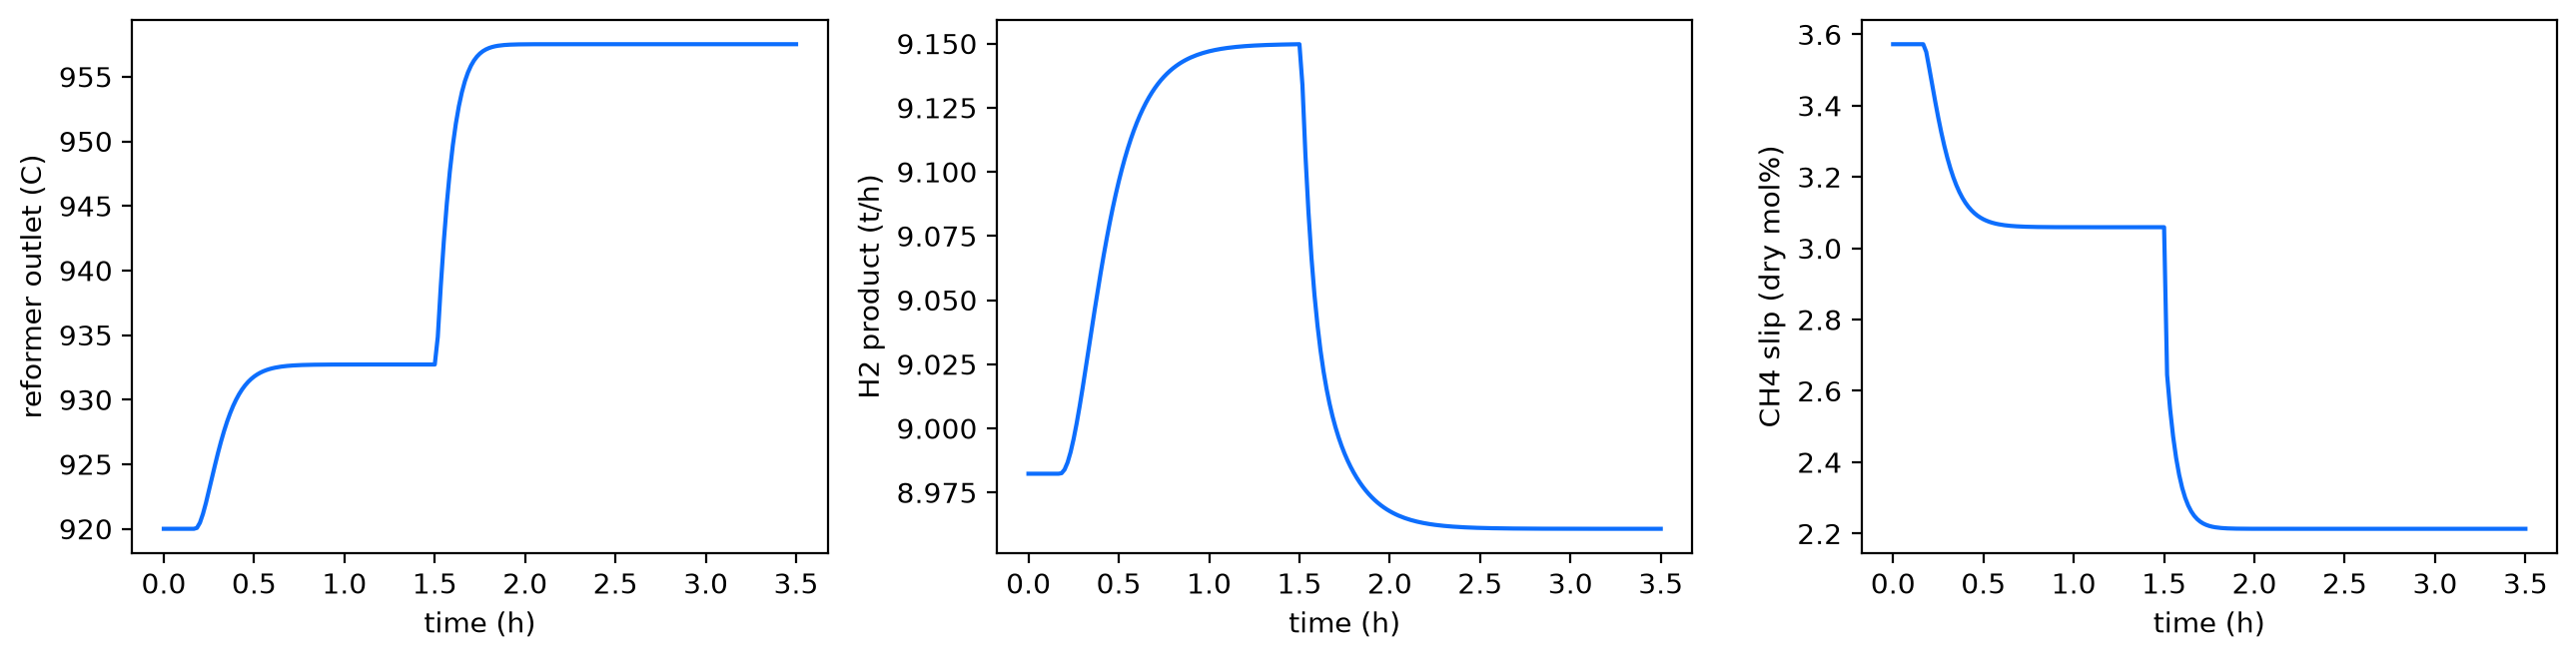

In [3]:
Q0 = plant.base_signals["firing"]
a = plant.args(steps={"firing": [(600.0, 0.03 * Q0)], "feed_rate": [(1.5 * H, -0.05)]})
t0 = time.time()
sim = plant.simulate(3.5 * H, args=a, n_save=211)
tr = plant.trajectory(sim, a)
print(f"3.5 h in {time.time() - t0:.0f} s ({int(sim.info.n_steps)} steps)")
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
t = np.asarray(tr["t"]) / H
ax[0].plot(t, np.asarray(tr["T_reformer_out"]) - 273.15); ax[0].set_ylabel("reformer outlet (C)")
ax[1].plot(t, np.asarray(tr["H2"]) * 2.016e-3 * 3.6); ax[1].set_ylabel("H2 product (t/h)")
ax[2].plot(t, 100 * np.asarray(tr["CH4_slip"])); ax[2].set_ylabel("CH4 slip (dry mol%)")
for x in ax: x.set_xlabel("time (h)")
plt.tight_layout()

A gradient through the trajectory: how much more hydrogen an hour later per watt of extra
firing at 5 minutes, by reverse mode through the diffrax solve and the tube cells' own nested
integrations.

In [4]:
def h2_at_1h(dQ):
    a = plant.args(steps={"firing": [(300.0, dQ)]})
    s = plant.simulate(H, args=a, n_save=2)
    return plant.observe(s.trajectory.t[-1], s.y_final, a)["H2"]

t0 = time.time()
g = jax.grad(h2_at_1h)(jnp.asarray(0.02 * Q0))
print(f"d(H2 at 1 h)/d(firing step) = {float(g) * 1e6:.4f} mol/s per MW ({time.time() - t0:.0f} s)")

d(H2 at 1 h)/d(firing step) = 7.6858 mol/s per MW (19 s)


## 2. The amine unit

The MDEA loop of the treating tests: one contactor on 980 mol/s of fuel gas with 2 % H2S and
2 % CO2, 120 mol/s of amine, a six-stage regenerator at 5 MW. The lean inventory holds 15
minutes of circulation, the rich one 10.

The sour gas rises 30 % at 5 minutes. The sweet gas's H2S jumps at once (the contactor's
trays are quasi-steady), then keeps rising over the next hour as the more heavily loaded
solvent comes back from the regenerator less well stripped.

built in 46 s (most of it the steady loop's solve and compile)


4 h in 48 s


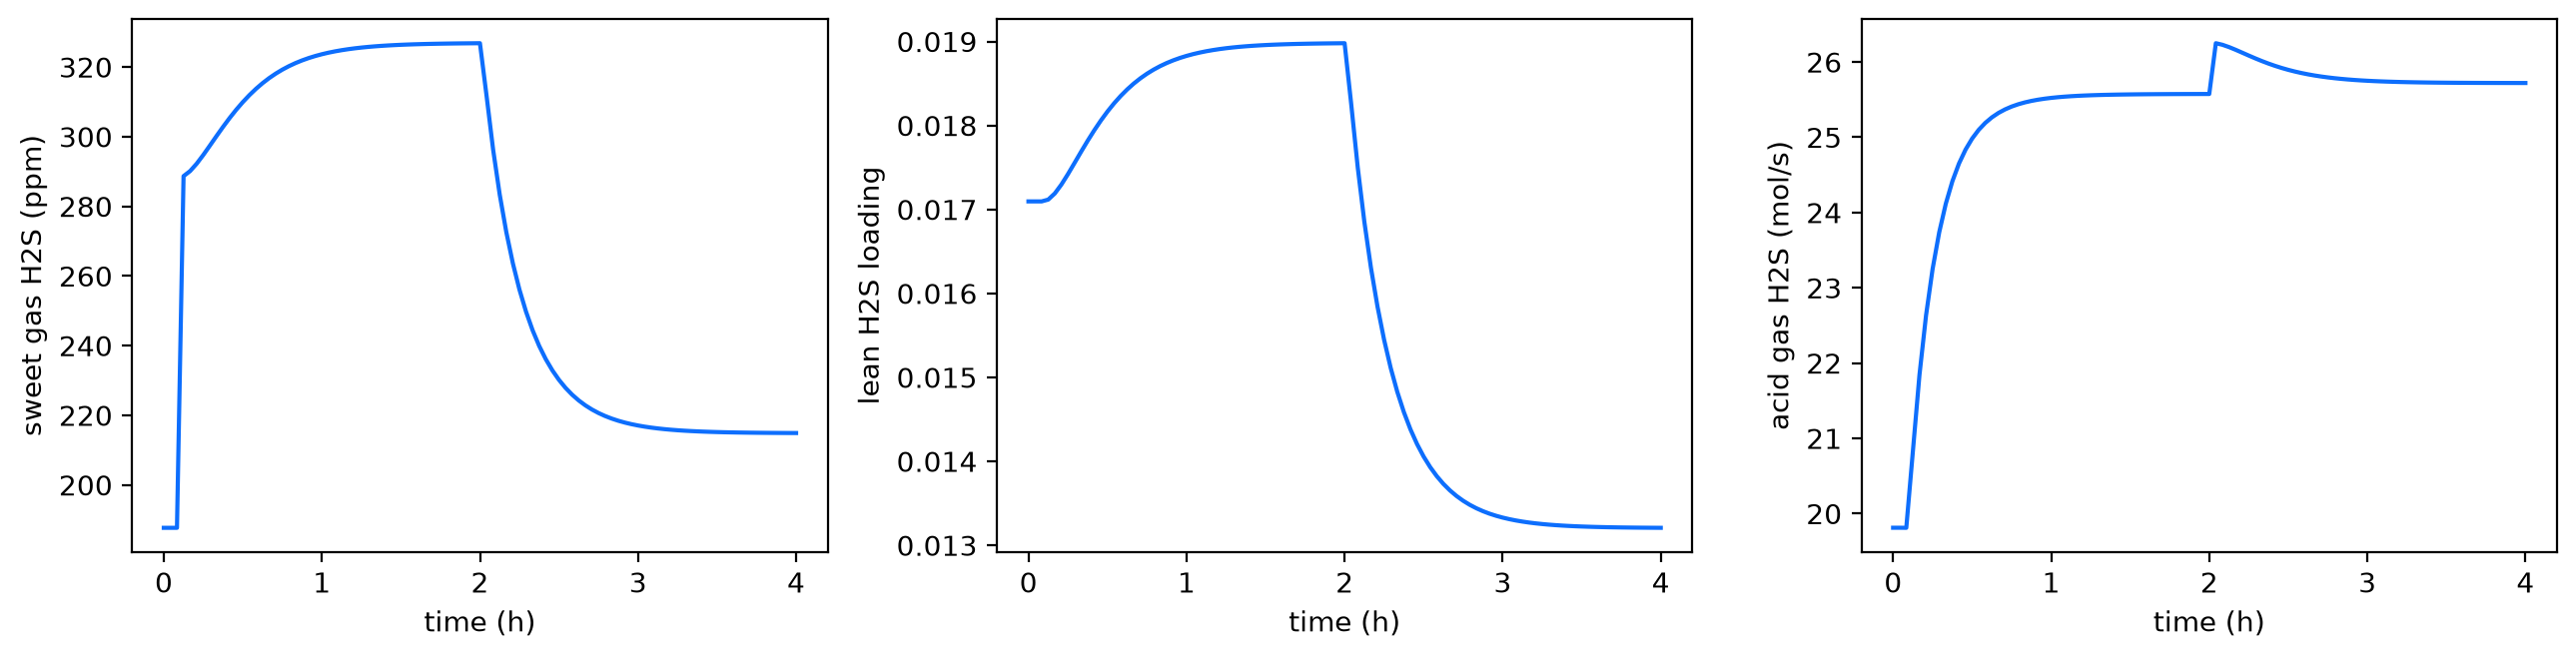

In [5]:
from difflow_refinery.treating import TrayParams
from difflow_refinery.treating.unit import AmineUnitParams, Contactor
tray = TrayParams(area=200.0, k_G=1e-5, k_L=1e-4)        # ILLUSTRATIVE tray coefficients
loop = AmineUnitParams("MDEA", 0.45, (Contactor("fuel", 120.0, 8, tray),), Q_reboiler=5e6, n_regenerator=6)
gas = {"F_methane": 700.0, "F_ethane": 150.0, "F_hydrogen": 110.0, "F_hydrogen_sulfide": 20.0,
       "F_carbon_dioxide": 20.0, "F_water": 1.0, "T": 313.15, "P": 7e5}
t0 = time.time()
amine = DynamicAminePlant.from_steady(loop, {"fuel": gas})
print(f"built in {time.time() - t0:.0f} s (most of it the steady loop's solve and compile)")
a = amine.args(steps={"gas_rate": [(300.0, 0.3)], "Q_reboiler": [(2.0 * H, 1.0e6)]})
t0 = time.time()
sim = amine.simulate(4 * H, args=a, n_save=97)
ta = amine.trajectory(sim, a)
print(f"4 h in {time.time() - t0:.0f} s")
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
t = np.asarray(ta["t"]) / H
ax[0].plot(t, ta["fuel.H2S_ppm"]); ax[0].set_ylabel("sweet gas H2S (ppm)")
ax[1].plot(t, ta["lean.alpha_H2S"], label="lean"); ax[1].set_ylabel("lean H2S loading")
ax[2].plot(t, ta["acid_gas.H2S"]); ax[2].set_ylabel("acid gas H2S (mol/s)")
for x in ax: x.set_xlabel("time (h)")
plt.tight_layout()

At 2 hours the reboiler duty is raised by 1 MW: the regenerator strips harder, and the lean
loading -- and with it the sweet gas -- comes down over the lean inventory's turnover.

## 3. The sulfur recovery unit

The SRU of the sulfur tests: 90 mol/s of H2S in the acid gas, two Claus beds, a SCOT tail-gas
unit whose acid gas is recycled to the furnace. Each converter's alumina is sized at a GHSV
of 1000 1/h, so a bed holds about half an hour of thermal inventory.

The acid gas rises 10 % at 5 minutes. Run open loop (the air held at its design flow) the
tail gas goes H2S-rich and the recovery falls; with the air-demand trim (an integral
controller on the tail gas's H2S - 2 SO2) the air follows the acid gas and the recovery comes
back.

built in 45 s; bed thermal times 21, 25, 17 min (Claus 1, Claus 2, hydrogenation)


open loop: 3 h in 67 s


air-demand control: 3 h in 32 s


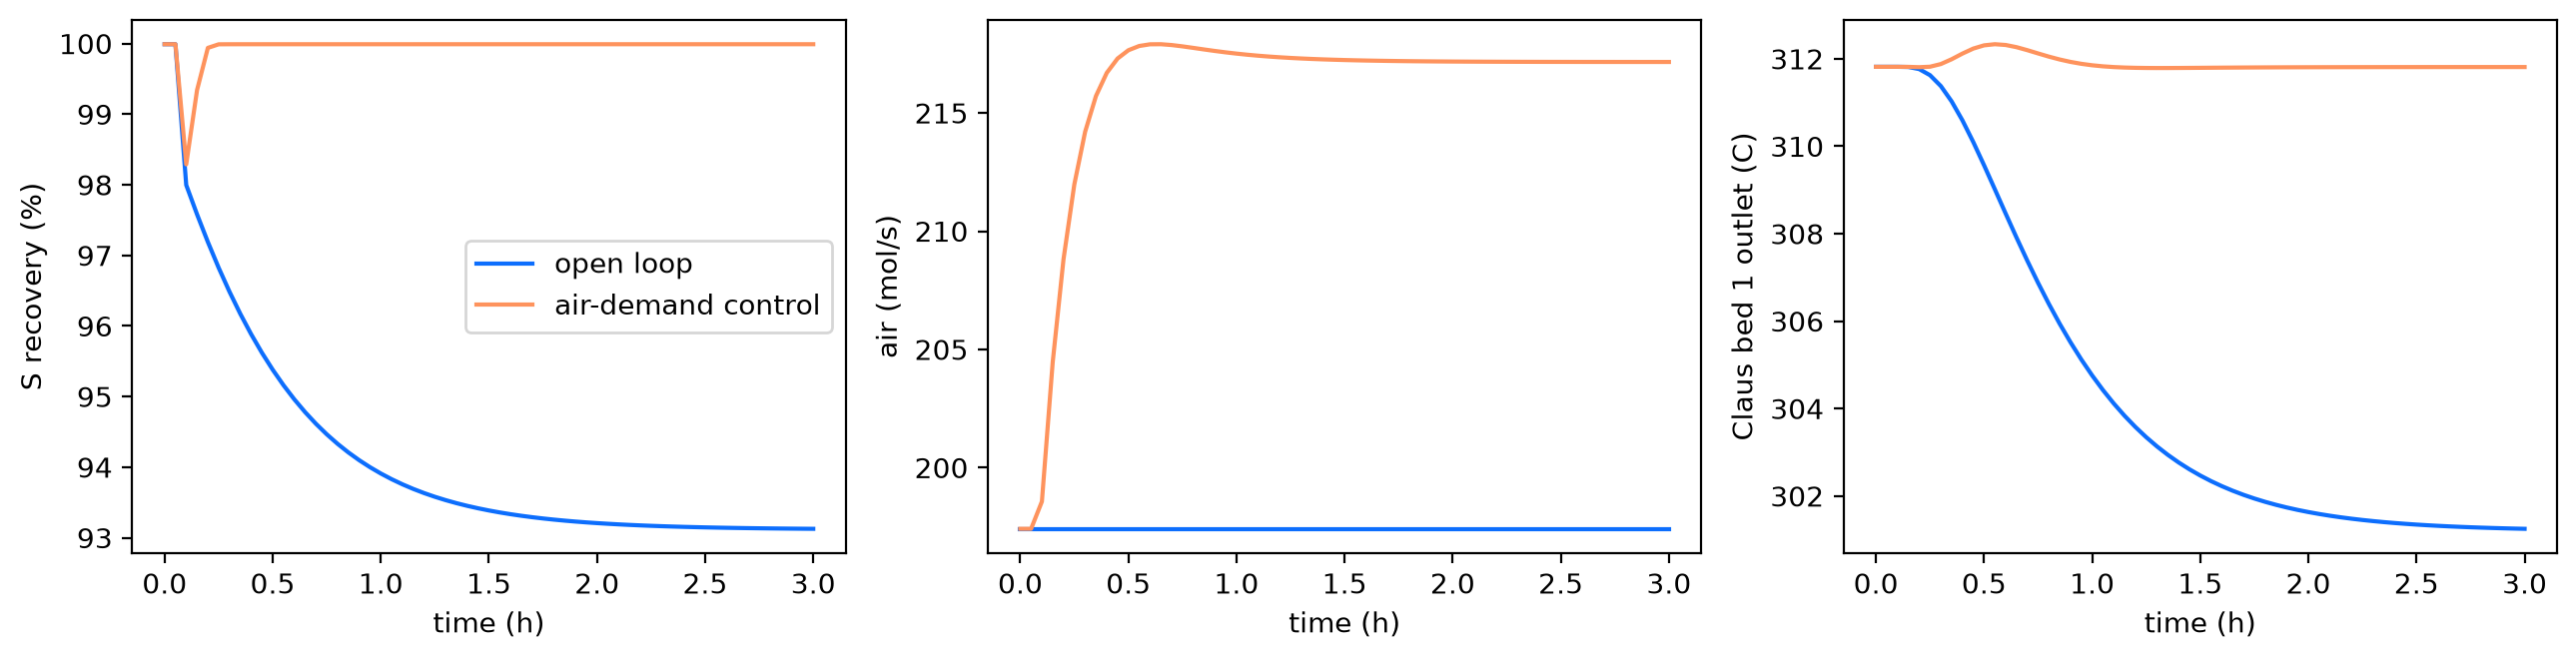

In [6]:
from difflow_refinery.sulfur import claus as cl, tgtu as tg
acid = make_stream({"hydrogen_sulfide": 90.0, "carbon_dioxide": 5.0, "water": 4.0, "methane": 1.0},
                   T=323.15, P=1.6e5)
beds = (cl.ConverterParams(523.15, hydrolysis=(0.9, 0.7)), cl.ConverterParams(483.15))
claus = cl.ClausParams(converters=beds, T_condensers=(443.15, 438.15, 413.15), T_air=473.15)
tgtu = tg.TGTUParams(tray=TrayParams(area=200.0, k_G=1e-5, k_L=1e-4), L=30.0, n_stages=12)
t0 = time.time()
sru = DynamicSRU.from_steady(acid, claus, tgtu)
sru_ctl = DynamicSRU.from_steady(acid, claus, tgtu, result=sru.steady, holdup=SRUHoldupParams(air_Ki=2e-3))
print(f"built in {time.time() - t0:.0f} s; bed thermal times "
      + ", ".join(f"{x / 60:.0f}" for x in sru.tau_beds) + " min (Claus 1, Claus 2, hydrogenation)")
a = sru.args(steps={"acid_rate": [(300.0, 0.1)]})
out = {}
for name, u in (("open loop", sru), ("air-demand control", sru_ctl)):
    t0 = time.time()
    s = u.simulate(3 * H, args=a, n_save=61)
    out[name] = u.trajectory(s, a)
    print(f"{name}: 3 h in {time.time() - t0:.0f} s")
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for name, tr_ in out.items():
    t = np.asarray(tr_["t"]) / H
    ax[0].plot(t, 100 * np.asarray(tr_["recovery"]), label=name)
    ax[1].plot(t, tr_["air"], label=name)
    ax[2].plot(t, np.asarray(tr_["bed1.T_out"]) - 273.15, label=name)
ax[0].set_ylabel("S recovery (%)"); ax[1].set_ylabel("air (mol/s)"); ax[2].set_ylabel("Claus bed 1 outlet (C)")
ax[0].legend()
for x in ax: x.set_xlabel("time (h)")
plt.tight_layout()

The bed outlet moves over tens of minutes: the thermal wave of the extra reaction heat
crossing the alumina. The recycle from the TGTU follows its solvent inventory's turnover.

## 4. The crude unit

The docs' test crude at 95 000 bbl/d into the docs' 30-stage column (three side strippers,
two pumparounds). The column's furnace spec, an overflash, is re-specified as the coil outlet
temperature it solves to, held by a 10-minute furnace lag. Draws and pumparound duties follow
the charge in proportion.

The coil outlet setpoint rises 5 K at 5 minutes, and the charge falls 5 % at 1.5 hours. The
cut temperatures follow the furnace through their holdups; the cut rates follow the charge.

built in 12 s: coil outlet 313.2 C


3 h in 99 s


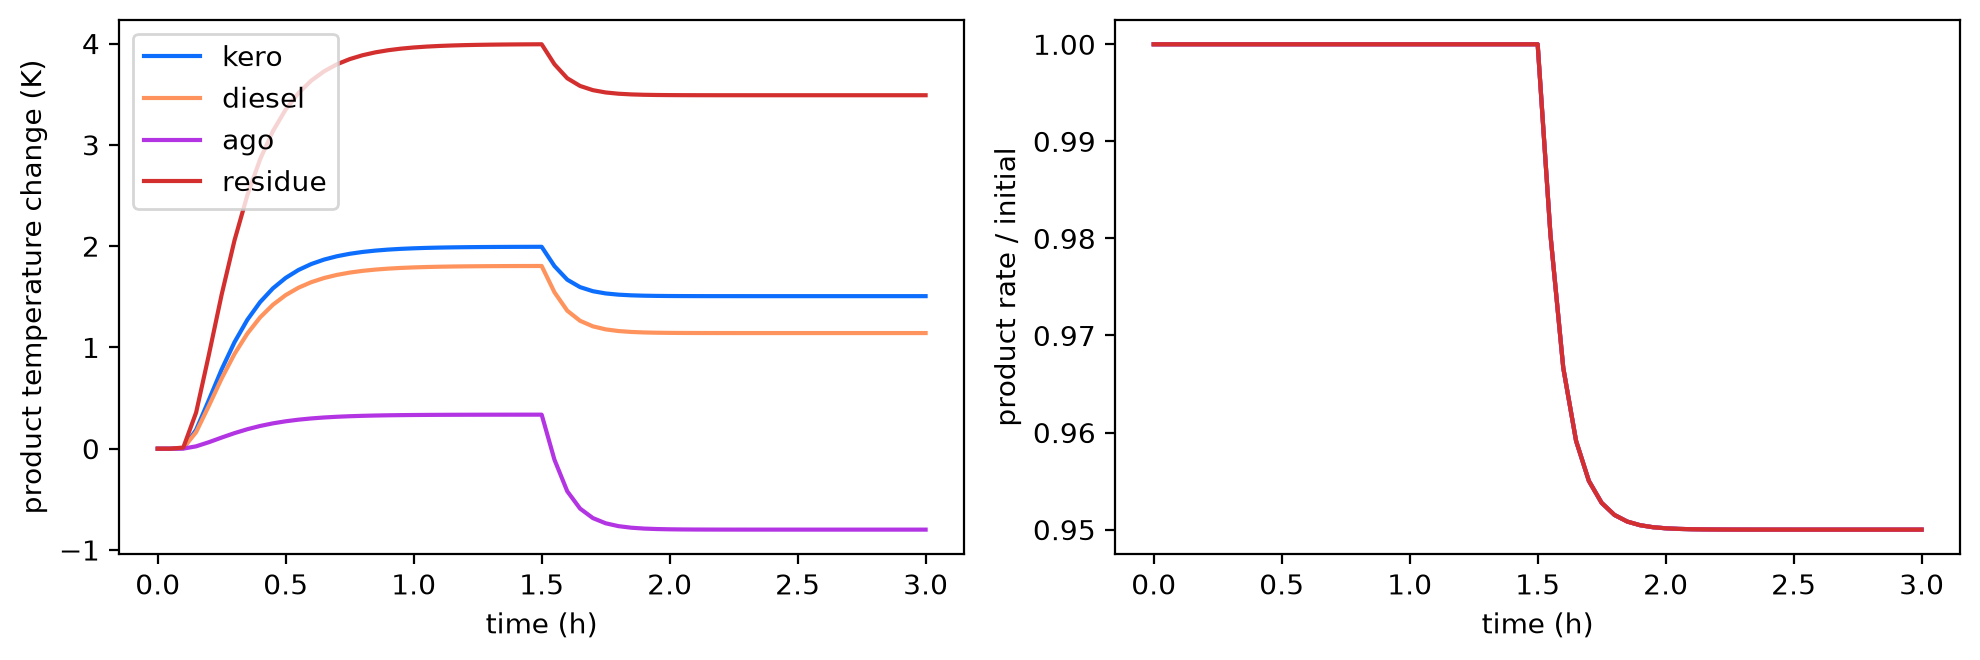

In [7]:
from difflow_refinery import Assay, ColumnThermo, characterize, column as cc
assay = Assay([0, 5, 10, 20, 30, 40, 50, 60, 70, 80, 90, 95, 100],
              [t + 273.15 for t in (-10, 60, 95, 150, 205, 260, 315, 370, 430, 500, 600, 680, 850)],
              sg=0.86, light_ends={"propane": 0.5, "n_butane": 1.0, "n_pentane": 1.5})
crude = characterize(assay)
thermo = ColumnThermo.from_characterization(crude)
kg_s = 95_000 * cc.BARREL / 86400.0 * float(crude.bulk_sg) * 999.016
feed = crude.stream(kg_s, T=273.15 + 240, P=6e5, basis="mass")
Vf = float(thermo.std_volume(jnp.stack([jnp.asarray(feed[f"F_{n}"]) for n in thermo.names])))
params = cc.CrudeColumnParams(
    n_stages=30, feed_stage=27, P_top=1.5e5, P_bottom=1.9e5, P_condenser=1.3e5,
    bottom_steam=150.0, steam_T=533.15,
    side_products=(cc.SideProduct("kero", 9, 4, steam=40.0), cc.SideProduct("diesel", 16, 4, steam=40.0),
                   cc.SideProduct("ago", 22, 3, steam=20.0)),
    pumparounds=(cc.Pumparound("pa1", 12, 10), cc.Pumparound("pa2", 19, 17)),
    specs=(cc.product_rate("naphtha", 0.20 * Vf), cc.product_rate("kero", 0.11 * Vf),
           cc.product_rate("diesel", 0.17 * Vf), cc.product_rate("ago", 0.05 * Vf),
           cc.pumparound_duty("pa1", 15e6), cc.pumparound_delta_t("pa1", 60.0),
           cc.pumparound_duty("pa2", 20e6), cc.pumparound_delta_t("pa2", 60.0), cc.overflash(0.05)),
    furnace=cc.Furnace(efficiency=0.85))
col = cc.CrudeColumn(params, thermo)
t0 = time.time()
cdu = DynamicCrudeUnit.from_steady(col, feed)
print(f"built in {time.time() - t0:.0f} s: coil outlet {float(cdu.base_signals['COT']) - 273.15:.1f} C")
a = cdu.args(steps={"COT": [(300.0, 5.0)], "feed_rate": [(1.5 * H, -0.05)]})
t0 = time.time()
sim = cdu.simulate(3 * H, args=a, n_save=61)
tc_ = cdu.trajectory(sim, a)
print(f"3 h in {time.time() - t0:.0f} s")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
t = np.asarray(tc_["t"]) / H
for n in ("kero", "diesel", "ago", "residue"):
    ax[0].plot(t, np.asarray(tc_[f"{n}.T"]) - np.asarray(tc_[f"{n}.T"])[0], label=n)
    ax[1].plot(t, np.asarray(tc_[f"{n}.volume"]) / np.asarray(tc_[f"{n}.volume"])[0], label=n)
ax[0].set_ylabel("product temperature change (K)"); ax[1].set_ylabel("product rate / initial")
ax[0].legend()
for x in ax: x.set_xlabel("time (h)")
plt.tight_layout()

## What this does and does not show

* Every unit rests at its steady unit's answer and returns to it after an upset (the gates
  quantify it); element or species balances close at every instant of every trajectory.
* The speeds are set by illustrative holdups and heat capacities. None of these transients
  has been compared with plant data or a published dynamic model.
* Not modelled: tray-by-tray column dynamics (the crude column, the amine contactor and
  regenerator are quasi-steady), pressure dynamics, a cycle-resolved PSA, wall heat in the
  sulfur plant's furnace and condensers, and controllers other than the air-demand trim.